# Consistent Sampling and Simulation: Demo
This notebook implements a minimal working version of [our paper](https://arxiv.org/abs/2506.17139), using [jax](https://github.com/jax-ml/jax). We also provide a [PyTorch version](https://colab.research.google.com/drive/1rbcNDwDduPw5QMulbOC-Pg6xGd4wGjej). However, the jax version is substantially faster (especially on CPU) and closer to our ground truth implementation, so we recommend using this version unless you specifically need PyTorch.

We will demonstrate that while diffusion models can accurately sample from a distribution, they often fail to model the energy (i.e., the unnormalized log-density) near the data manifold at $t \approx 0$, a well known limitation. While this does not impact iid sampling, it poses challenges when one wants to extract forces from diffusion models for molecular dynamics (MD) simulation, as the underlying scores become inaccurate. This notebook highlights this inconsistency and shows how it can be addressed.

We apply our method to two illustrative examples: a simple 2D double-well potential, where we visualize the learned energy landscape, and the Müller-Brown potential, where we additionally perform MD simulations using the learned forces.

This notebook presents a simplified version of our method, without optimizations such as batch processing, EMA parameters, mixture-of-experts, or extensive hyperparameter tuning.

In [ ]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import optax
import flax.linen as nn
from flax.training.train_state import TrainState
from dataclasses import dataclass
from typing import Callable, Sequence, Tuple
from functools import partial
from tqdm import tqdm, trange

## Generating the Training Data
We use a 2D double-well potential composed of two Gaussian modes with different weights:
$$
U = \frac{1}{5} \mathcal{N} ([-5, -5] , 1) +  \frac{4}{5} \mathcal{N} ([+5, +5] , 1)
$$
This creates an asymmetric bimodal distribution where the top-right mode has higher probability mass.

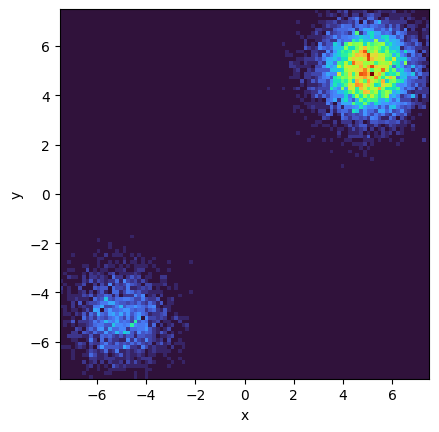

In [ ]:
rng = np.random.default_rng(seed=0)

# Create the training data
num_samples = 10_000
data = rng.normal(size=(num_samples, 2))
data[: num_samples // 5] += np.array([-5, -5])  # 20% from left mode
data[num_samples // 5 :] += np.array([5, 5])  # 80% from right mode
data = jnp.array(data)


@jax.jit
def double_well_2d_density(x):
    """Analytical density of the double well potential."""
    return 1 / 5 * jax.scipy.stats.multivariate_normal.pdf(
        x, jnp.array([-5, -5]), 1
    ) + 4 / 5 * jax.scipy.stats.multivariate_normal.pdf(x, jnp.array([5, 5]), 1)


def plot_double_well_2d(data):
    """Plot the data of the shape (BS, 2) as a histogram."""
    # filter out everything outside of -7.5, 7.5, so that is actually 100 bins
    plt.hist2d(*data.T, bins=100, cmap="turbo", range=[[-7.5, 7.5], [-7.5, 7.5]])

    plt.xlabel("x")
    plt.xlim(-7.5, 7.5)
    plt.ylabel("y")
    plt.ylim(-7.5, 7.5)

    plt.gca().set_aspect("equal")


plot_double_well_2d(data)

## Energy-based diffusion model
In this work, we use energy-based diffusion models, where the score is defined as the gradient of a learned energy function. This parameterization ensures that the score field is conservative, which leads to more stable and physically meaningful forces, which is an important property for MD simulation.

In practice, our model predicts the energy, and the score is obtained by taking the gradient with respect to the input:
$$
\nabla_{\boldsymbol{x}} \log p_t(\boldsymbol{x}) \approx \nabla_{\boldsymbol{x}} \log p^{\boldsymbol{\theta}}_t(\boldsymbol{x}) = \nabla_{\boldsymbol{x}} NNET(\boldsymbol{x}, t),
$$
where the gradient is computed via automatic differentiation at each forward pass.

In [ ]:
@dataclass
class MLP(nn.Module):
    """Energy-based MLP; score is -∇_x U(x, t)."""

    hidden_dims: Sequence[int]
    activation: Callable[[jnp.ndarray], jnp.ndarray]

    def _prepare_input(self, x, t):
        """Prepare the input for the model by concatenating the time and the data into a single tensor."""
        if t.ndim == 1:
            t = t.reshape(-1, 1)

        t_feat = jnp.concatenate(
            [
                t - 0.5,
                # add some fourier features to make training easier
                jnp.cos(2 * jnp.pi * t),
                jnp.sin(2 * jnp.pi * t),
                -jnp.cos(4 * jnp.pi * t),
            ],
            axis=-1,
        )

        return jnp.concatenate([x, t_feat], axis=-1)

    def score(self, x, t):
        return -jax.grad(lambda x: self.energy(x, t).sum())(x)

    @nn.compact
    def energy(self, x, t):
        """
        Compute the energy function of the model with a simple feed forward MLP.
        The energy is the negative log-density, so the score is the gradient of the energy.
        """
        h = self._prepare_input(x, t)
        for dim in self.hidden_dims:
            h = nn.Dense(dim)(h)
            h = self.activation(h)

        return nn.Dense(1)(h)  # the output is the energy, so a single scalar

    def __call__(self, x, t):
        return self.score(x, t)

## Construct the Diffusion Process
We use a Variance-Preserving (VP) formulation for the diffusion process, defined via a stochastic differential equation (SDE). This formulation determines how noise is added during the forward process and is critical for training and sampling. The SDE has the form
$$
d\boldsymbol{x} = -\frac{1}{2} \beta(t) \boldsymbol{x} + \sqrt{\beta(t)} d \boldsymbol{w},
$$
where $\beta(t)$ is a time-dependent noise schedule and $w$ denotes standard Brownian motion. An extension to Variance-Exploding (VE) is straightforward but would require adjustments here and in the Fokker–Planck regularization.

This implementation is adapted from [Ben Boy's diffusionjax](https://github.com/bb515/diffusionjax/blob/master/diffusionjax/sde.py).

In [ ]:
def get_linear_beta_function(beta_min, beta_max):
    """
    Returns:
        beta(t): Linear beta schedule as a function of time.
        log_mean_coeff(t): Logarithm of the mean coefficient in the VP SDE.
    """

    def beta(t):
        return beta_min + t * (beta_max - beta_min)

    def log_mean_coeff(t):
        return -0.5 * t * beta_min - 0.25 * t**2 * (beta_max - beta_min)

    return beta, log_mean_coeff


class VP:
    """Variance preserving (VP) SDE, a.k.a. time rescaled Ohrnstein Uhlenbeck (OU) SDE."""

    def __init__(self, beta_min=0.1, beta_max=20.0):
        self.beta, self.log_mean_coeff = get_linear_beta_function(beta_min=beta_min, beta_max=beta_max)

    def sde(self, x, t):
        """Drift and diffusion coefficients of the forward SDE."""
        beta_t = self.beta(t)
        diffusion = jnp.sqrt(beta_t)
        drift = -0.5 * beta_t[:, None] * x
        return drift, diffusion

    def std(self, t):
        return jnp.sqrt(self.variance(t))

    def variance(self, t):
        return 1.0 - jnp.exp(self.log_mean_coeff(t) * 2)

    def marginal_prob(self, x, t):
        """Mean and std of the marginal at time t."""
        return jnp.exp(self.log_mean_coeff(t)) * x, self.std(t)

    def reverse(self, score):
        """Return the reverse-time SDE, parameterized by the score function."""
        return RVP(score, self.sde, self.beta, self.log_mean_coeff)


class RSDE:
    """Generic reverse-time SDE class."""

    def __init__(self, score, forward_sde, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.score = score
        self.forward_sde = forward_sde

    def sde(self, x, t):
        """Compute the drift and diffusion of the reverse SDE."""
        drift, diffusion = self.forward_sde(x, t)
        drift = -drift + diffusion[:, None] ** 2 * self.score(x, t)
        return drift, diffusion


class RVP(RSDE, VP):
    """Reverse SDE using the VP forward process."""

    pass


# Define the VP SDE with common choices for beta_min and beta_max
vp = VP(beta_min=0.1, beta_max=20.0)

## Define the Model and Optimizer
We now initialize the energy-based model and set up the optimizer. The model is a simple multilayer perceptron (MLP) with three hidden layers and Swish activation. We use the AdamW optimizer for training.

In [ ]:
model = MLP([92, 92, 92], nn.swish)

# Initialize model parameters
dummy_x = jnp.ones([1, data.shape[1]])
dummy_t = jnp.zeros([1, 1])
init_params = model.init(jax.random.PRNGKey(0), dummy_x, dummy_t)

# Set up the optimizer and training state
optimizer = optax.adamw(learning_rate=3e-4)
state = TrainState.create(apply_fn=model.apply, params=init_params, tx=optimizer)

### Define the Standard Diffusion Loss
We train the diffusion model using the standard denoising score matching loss, which minimizes the squared error between the true noise and the model-predicted score.

In [ ]:
def get_score_fn(model, params):
    """Returns a function that computes the model's score ∇_x log p(x, t)."""

    def score(x, t):
        return model.apply(params, x, t)

    return score


def get_energy_fn(model, params):
    """Returns a function that computes the energy U(x, t)."""

    def energy(x, t=None):
        if t is None:
            t = jnp.zeros((x.shape[0], 1))
        return model.apply(params, x, t, method="energy")

    return energy


def perturb(t, rng, data):
    """
    Perturb the data x(0) using the forward SDE to get x(t).

    Returns:
        x_t: noisy sample
        noise: sampled noise
        std: standard deviation at time t
    """
    mean, std = vp.marginal_prob(data, t)
    rng, step_rng = jax.random.split(rng)
    noise = jax.random.normal(step_rng, data.shape)
    return mean + std * noise, noise, std  # noisy sample


def errors(noise, score, std):
    """
    Returns:
    A Monte-Carlo approximation to the (likelihood weighted) score errors. And the perturbed data
    """
    return noise + score * std


def diffusion_loss_fn(params, key, batch, ts):
    """Computes the denoising score matching loss."""
    x_t, noise, std = perturb(ts, key, batch)
    score = get_score_fn(model, params)(x_t, ts)
    e = errors(noise, score, std)

    return jnp.mean(e**2)

## Training a Standard Diffusion Model
We train the diffusion model using denoising score matching. At each step, we sample a random time $t \sim \mathcal{U} (1e-5, 1)$, perturb the data using the forward SDE, and optimize the model to match the true score.

100%|██████████| 100/100 [00:23<00:00,  4.34it/s]


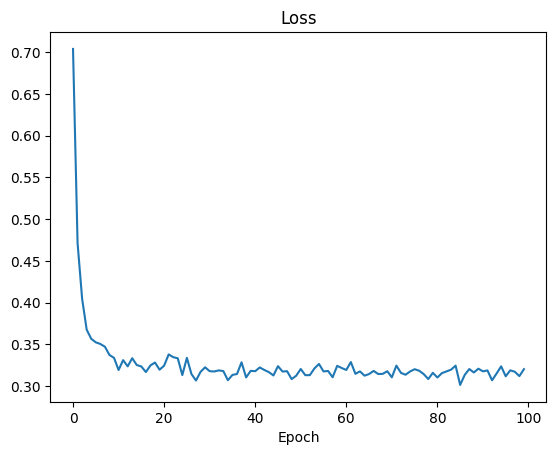

In [ ]:
def train_loop(state, data, loss_fn, epochs, BS, key):
    @jax.jit
    def train_step(state, batch, key):
        key, time_key = jax.random.split(key)
        # sample t uniformly from [1e-5, 1.0]
        ts = jax.random.uniform(time_key, (batch.shape[0], 1), minval=1e-5, maxval=1.0)

        loss, grads = jax.value_and_grad(loss_fn)(state.params, key, batch, ts)
        state = state.apply_gradients(grads=grads)
        return state, loss

    losses = []
    for _ in trange(epochs):
        key, shuffle_key, epoch_key = jax.random.split(key, 3)
        steps_per_epoch = min(data.shape[0] // BS, data.shape[0])

        # do random permutations of the data and divide into batches
        perms = jax.random.permutation(shuffle_key, data.shape[0])
        perms = perms[: steps_per_epoch * BS]  # Skip incomplete batches
        perms = perms.reshape((steps_per_epoch, BS))

        cur_epoch_losses = []
        for perm in perms:
            epoch_key, step_key = jax.random.split(epoch_key)
            state, loss = train_step(state, data[perm], step_key)
            cur_epoch_losses.append(loss)

        losses.append(jnp.mean(jnp.array(cur_epoch_losses)))

    plt.title("Loss")
    plt.plot(losses)
    plt.xlabel("Epoch")

    return state


diffusion_state = train_loop(state, data, diffusion_loss_fn, 100, 128, jax.random.PRNGKey(0))

## Evaluate the Model
We now evaluate the trained diffusion model by:
1. Sample from it using the reverse SDE (standard iid sampling)
2. Comparing the learned unnormalized density with the true data density.

In [ ]:
def sample(key, params, num_samples, num_steps, denoise_last=False):
    """
    Generate samples from the diffusion model using the reverse SDE.
    This corresponds to standard i.i.d. diffusion sampling.
    """
    ts = jnp.linspace(0, 1, num_steps)[..., None]
    dt = ts[1] - ts[0]

    key = jax.random.PRNGKey(0)
    key, sample_key = jax.random.split(key)
    x0 = jax.random.normal(sample_key, (num_samples, data.shape[1]))

    reverse_vp = vp.reverse(get_score_fn(model, params))

    @jax.jit
    def step_fn(key, x, t):
        vec_t = jnp.full((num_samples,), t)

        drift, diffusion = reverse_vp.sde(x, vec_t)
        f = drift * dt
        G = diffusion * jnp.sqrt(dt)
        noise = jax.random.normal(key, x.shape)
        x_mean = x + f
        x = x_mean + G[:, None] * noise
        return x, x_mean

    x = x0
    x_mean = x

    for t in tqdm(reversed(ts), total=len(ts), desc="Sampling"):
        key, step_key = jax.random.split(key)
        x, x_mean = step_fn(step_key, x, t)

    return x_mean if denoise_last else x

Sampling: 100%|██████████| 200/200 [00:04<00:00, 41.93it/s]


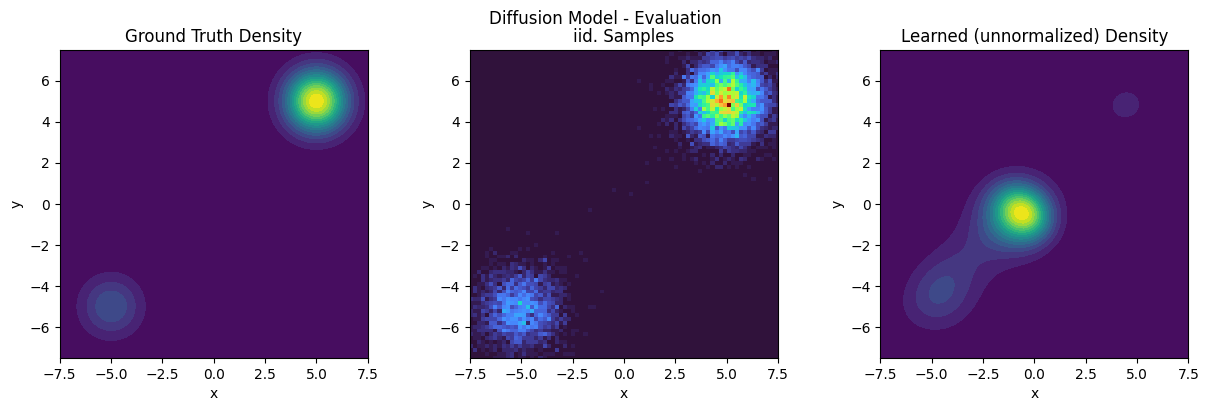

In [ ]:
def evaluate(key, params):
    # generate samples
    samples = sample(key, params, num_samples=data.shape[0], num_steps=200)

    # define a grid to evaluate the energy
    x = jnp.linspace(-7.5, 7.5, 100)
    y = jnp.linspace(-7.5, 7.5, 100)
    grid = jnp.stack(jnp.meshgrid(x, y), axis=-1).reshape(-1, 2)

    plt.figure(figsize=(15, 4))

    plt.subplot(1, 3, 1)
    plt.title("Ground Truth Density")
    plt.contourf(x, y, double_well_2d_density(grid).reshape(100, 100), levels=20)
    plt.gca().set_aspect("equal")
    plt.xlabel("x")
    plt.ylabel("y")

    plt.subplot(1, 3, 2)
    plt.title("iid. Samples")
    plot_double_well_2d(samples)

    plt.subplot(1, 3, 3)
    plt.title("Learned (unnormalized) Density")
    plt.contourf(x, y, jnp.exp(-get_energy_fn(model, params)(grid)).reshape(100, 100), levels=20)
    plt.gca().set_aspect("equal")
    plt.xlabel("x")
    plt.ylabel("y")


evaluate(jax.random.PRNGKey(0), diffusion_state.params)
plt.suptitle("Diffusion Model - Evaluation")
plt.show()

We observe that the diffusion model can match the data distribution well under iid sampling: both modes are captured and samples look realistic. However, the learned energy (i.e. log density)tells a different story. It distorts the relative weight of the modes and introduces artifacts, especially near the less-populated mode.

This discrepancy illustrates a key failure mode of standard diffusion models. Although they are excellent samplers, they do not learn consistent energies/scores. As a result, when we use the learned score as a force field (e.g., for MD simulation), the model behaves inconsistently and fails to reproduce the correct stationary distribution.

How can we fix this inconsistency between sampling and energy modeling? In the next part, we'll introuce a Fokker-Planck-based regularization term that encourages the model to satisfy the underlying evolution equation, leading to more physically consistent behavior.

## Fokker-Planck Regularization
The Fokker-Planck equation (here in log form)
$$
\partial_t \log p_t(\boldsymbol{x})=\frac{1}{2} g^2(t)\left[\operatorname{div}_{\boldsymbol{x}}\left(\nabla_{\boldsymbol{x}} \log p_t\right)+\left\|\nabla_{\boldsymbol{x}} \log p_t\right\|_2^2\right]-\left\langle\boldsymbol{f}, \nabla_{\boldsymbol{x}} \log p_t\right\rangle-\operatorname{div}_{\boldsymbol{x}}(\boldsymbol{f}) \triangleq \mathcal{F}_p(\boldsymbol{x}, t)
$$
describes how the log-density evolves over time under the forward SDE. Since diffusion models typically yield accurate scores at most time steps (otherwise iid sampling would not work), we can use the Fokker–Planck equation to regularize the model and improve its behavior near $t \approx 0$, where standard training tends to fail.

To that end, we define a consistency based on the Fokker-Planck equation as a regularization and minimize the distance of our model to it
$$
\mathcal{L}_{\mathrm{FP}}\left[\log p^{\boldsymbol{\theta}}\right](\boldsymbol{x}, t) = D^{-2} \left\|\mathcal{F}_{p^{\boldsymbol{\theta}}}(\boldsymbol{x}, t)-\partial_t \log p_t^{\boldsymbol{\theta}}(\boldsymbol{x})\right\|_2^2.$$

Combining this with the denoising score matching loss gives our total loss:
$$
\mathcal{L} \left[ \log p^{\boldsymbol{\theta}} \right] = \mathcal{L}_{\text{DSM}} \left[ \nabla_{\mathbf{x}} \log p^{\boldsymbol{\theta}} \right] + \alpha \cdot \mathcal{L}_{\text{FP}} \left[ \log p^{\boldsymbol{\theta}} \right],
$$
where $\alpha$ controls the regularization strength.

Although the exact formulation is expensive to compute (especially in high dimensions), our paper introduces a weak-form approximation that only requires first-order derivatives. Below, we implement this approximation.

100%|██████████| 100/100 [01:14<00:00,  1.35it/s]


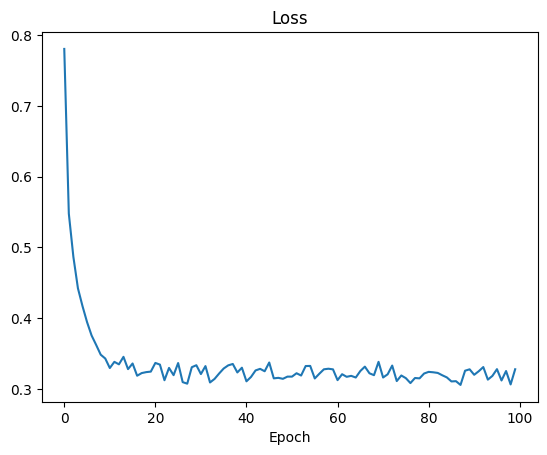

In [ ]:
sigma = 1e-4 # noise scale for weak-form approximation

# This follows https://arxiv.org/abs/2210.04296
def finite_diff_t(fn, x, t, hs=0.001, hd=0.0005):
    fn_p, fn_c, fn_m = fn(x, t + hd), fn(x, t), fn(x, t - hs)

    up = hs**2 * fn_p + (hd**2 - hs**2) * fn_c - hd**2 * fn_m
    low = hs * hd * (hd + hs)
    return up / low

# This is a relatively straightforward implementation of the energy-based Fokker–Planck loss.
# For clarity, we avoid batching all forward passes together, even though it would be more efficient.
# Additionally, we recompute energies and scores separately; these could be fused into a single forward pass
# for better performance by extending the model to return both at once.
def consistent_loss_fn(params, key, batch, ts, alpha):
    """Compute weak-form approximation of Fokker-Planck residual."""
    energy_fn = lambda x, t: -get_energy_fn(model, params)(x, t)
    score_fn = get_score_fn(model, params)

    _, diffusion = vp.sde(batch, ts)
    g_pow = diffusion**2

    key, reg_key = jax.random.split(key)
    v = sigma * jax.random.normal(reg_key, shape=(2, *batch.shape))

    x_t, noise, std = perturb(ts, key, batch)
    x1_p, x1_m = x_t + v[0], x_t - v[0]
    x2_p, x2_m = x_t + v[1], x_t - v[1]

    def compute_estimate(x_p, v, score_p, score_m, dlogpdt_p):
        R = 1 / 2 * g_pow * (v / sigma) * (score_p - score_m) / (2 * sigma)
        R = jnp.sum(R, axis=1)

        # for VP f(x, t) = -0.5 beta(t) * x, and hence the divergence is -0.5 beta(t)
        div_f = -1 / 2 * g_pow

        return R + (
            1 / 2 * g_pow * jnp.linalg.norm(score_p, 2, axis=1)[:, None] ** 2  # 1/2 * g**2 *||score (x+v)||^2_2
            + 1 / 2 * g_pow * jnp.sum(x_p * score_p, axis=1)[:, None]  # <f(x + v, t), score (x + v)>
            - div_f  # - div_x f(x + v)
            - dlogpdt_p  # - \partial_t log p(x + v)
        )[:, 0]

    # compute Fokker–Planck residuals
    R1 = compute_estimate(x1_p, v[0], score_fn(x1_p, ts), score_fn(x1_m, ts), finite_diff_t(energy_fn, x1_p, ts))
    R2 = compute_estimate(x2_p, v[1], score_fn(x2_p, ts), score_fn(x2_m, ts), finite_diff_t(energy_fn, x2_p, ts))

    D = batch.shape[1]  # data dimension
    fp_loss = jnp.mean(R1 * R2) / D**2

    # standard diffusion loss
    score = score_fn(x_t, ts)
    e = errors(noise, score, std)
    diffusion_loss = jnp.mean(e**2)

    return diffusion_loss + alpha * fp_loss

consistent_state = train_loop(state, data, partial(consistent_loss_fn, alpha=0.01), 100, 128, jax.random.PRNGKey(0))

### Evaluation
We now evaluate the model trained with Fokker-Planck regularization. As shown below, the learned energy is much more consistent with the sampling distribution, accurately capturing both the structure and relative weights of the modes.

Sampling: 100%|██████████| 200/200 [00:05<00:00, 35.40it/s]


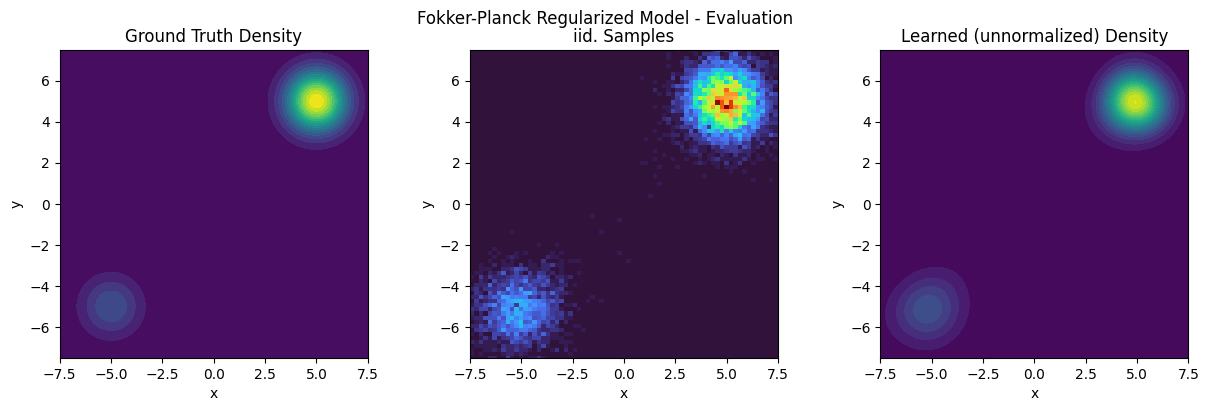

In [ ]:
evaluate(jax.random.PRNGKey(0), consistent_state.params)
plt.suptitle("Fokker-Planck Regularized Model - Evaluation")
plt.show()

You can experiment with different values of the regularization strength $\alpha$ to observe how it affects the trade-off between sampling quality and energy consistency. A small value (e.g., $\alpha=0.0001$) may preserve better sampling, while a larger value enforces stronger consistency but may distort samples if over-regularized.

# Simulation
If we train a diffusion model on samples from a Boltzmann distribution of the form
$$
p \propto \exp \left(-\frac{U(\boldsymbol{x})}{k_B T}\right),
$$
then the model’s score at $t=0$ approximates the gradient of the log-density
$$
\begin{aligned}
\boldsymbol{s}^{\boldsymbol{\theta}}(\boldsymbol{x}, t=0) & \approx \nabla_x \log p_{t=0}(\boldsymbol{x}) \\
& =\nabla_x \log \exp \left(-\frac{U(\boldsymbol{x})}{k_B T}\right) - \nabla_{\boldsymbol{x}} \log Z \\
& =-\nabla_x \frac{U(\boldsymbol{x})}{k_B T} -0,
\end{aligned}$$
where $z$ is a normalizing constant. This reveals that the score function at $t=0$ is proportional to the negative force (i.e., gradient of the potential energy), and can therefore be used as a surrogate for MD simulation.

These simulations can be described by the Langevin dynamics SDEs:
$$
\begin{aligned} \mathrm{d} \boldsymbol{x} &=\boldsymbol{v} \mathrm{d} t, \\
 \boldsymbol{M} \mathrm{~d} \boldsymbol{v} &=-\nabla_{\boldsymbol{x}} U(\boldsymbol{x}) \mathrm{d} t-\gamma \boldsymbol{M} \boldsymbol{v} \mathrm{d} t+\sqrt{2 \gamma k_B T} \mathrm{~d} \boldsymbol{w}_t.
\end{aligned}$$

## Müller Brown Potential
To demonstrate how our model can be used for simulation, we generate training data from a physical potential. Specifically, we use the Müller–Brown potential, a standard 2D energy landscape with multiple minima. We simulate this system using Langevin dynamics, which allows us to sample from the corresponding Boltzmann distribution.

Below, we define the potential, compute forces via automatic differentiation, and simulate a trajectory using a Langevin integrator.

In [ ]:
kbT = 23.0
mass = jnp.array([0.5, 0.5])
num_mueller_brown_samples = 50_000
num_mueller_brown_steps = 5  # decorrelates the data a bit


@jax.jit
def mueller_brown_potential(xs: jnp.ndarray, beta: float = 1.0) -> jnp.ndarray:
    """Compute the Müller-Brown potential energy."""
    if xs.ndim == 1:
        xs = xs.reshape(1, -1)

    x, y = xs[:, 0], xs[:, 1]
    e1 = -200 * jnp.exp(-((x - 1) ** 2) - 10 * y**2)
    e2 = -100 * jnp.exp(-(x**2) - 10 * (y - 0.5) ** 2)
    e3 = -170 * jnp.exp(-6.5 * (0.5 + x) ** 2 + 11 * (x + 0.5) * (y - 1.5) - 6.5 * (y - 1.5) ** 2)
    e4 = 15.0 * jnp.exp(0.7 * (1 + x) ** 2 + 0.6 * (x + 1) * (y - 1) + 0.7 * (y - 1) ** 2)
    return beta * (e1 + e2 + e3 + e4)


@jax.jit
def mueller_brown_force(xs: jnp.ndarray) -> jnp.ndarray:
    """Compute the force as the negative gradient of the potential."""
    return jax.grad(lambda _x: -mueller_brown_potential(_x).sum())(xs)


def create_langevin_step_function(
    force: Callable[[jnp.ndarray], jnp.ndarray], mass: jnp.ndarray, gamma: float, num_steps: int, dt: float, kbT: float
) -> Callable[[jnp.ndarray, jnp.ndarray, jnp.ndarray], Tuple[jnp.ndarray, jnp.ndarray]]:
    """
    Returns a function that performs Langevin integration for a given number of steps.
    Implementation is based on OpenMM's Langevin integrator.
    """

    @jax.jit
    def step_single(x: jnp.ndarray, v: jnp.ndarray, key: jax.random.PRNGKey) -> Tuple[jnp.ndarray, jnp.ndarray]:
        """Perform one step of forward langevin as implemented in openmm 8.2."""
        assert x.shape == v.shape, f"Position and velocity should have the same shape. Shape {x.shape} != {v.shape}."
        alpha = jnp.exp(-gamma * dt)
        f_scale = (1 - alpha) / gamma
        new_v_det = alpha * v + f_scale * force(x) / mass
        new_v = new_v_det + jnp.sqrt(kbT * (1 - alpha**2) / mass) * jax.random.normal(key, x.shape)

        return x + dt * new_v, new_v

    if num_steps == 1:
        return step_single

    @jax.jit
    def step_n(x: jnp.ndarray, v: jnp.ndarray, key: jax.random.PRNGKey) -> Tuple[jnp.ndarray, jnp.ndarray]:
        for _ in range(num_steps):
            key, step_key = jax.random.split(key)
            x, v = step_single(x, v, step_key)
        return x, v

    return step_n


def simulate_mueller_brown(key, force: Callable[[jnp.ndarray], jnp.ndarray], num_samples: int, num_steps: int = 1):
    """Simulate Langevin dynamics on the Müller-Brown potential."""
    step_fn = create_langevin_step_function(force, mass=mass, gamma=1.0, num_steps=num_steps, dt=5e-3, kbT=kbT)

    x = jnp.array([-0.55828035, 1.44169])

    # Sample the starting velocity from the Boltzmann distribution
    key, velocity_key = jax.random.split(key)
    v = jnp.sqrt(kbT / mass) * jax.random.normal(velocity_key, (2,))

    trajectory = []
    for _ in trange(num_samples, desc="Simulating"):
        key, step_key = jax.random.split(key)
        x, v = step_fn(x, v, step_key)
        trajectory.append(x)

    return jnp.stack(trajectory)


# Generate training samples from the Boltzmann distribution of the Müller-Brown potential
trajectory = simulate_mueller_brown(
    jax.random.PRNGKey(0), mueller_brown_force, num_samples=num_mueller_brown_samples, num_steps=num_mueller_brown_steps
)

Simulating: 100%|██████████| 50000/50000 [00:16<00:00, 2976.06it/s]


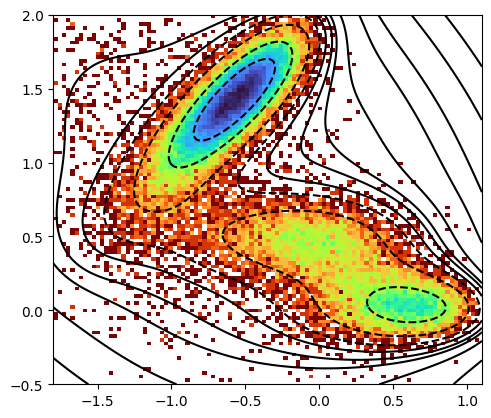

In [ ]:
def plot_mueller_brown(samples):
    bins = 150
    (x_min, x_max), (y_min, y_max) = jnp.array([[-1.8, 1.1], [-0.5, 2.0]])
    # make a nice contour plot of the potential
    x, y = jnp.linspace(x_min, x_max, bins), jnp.linspace(y_min, y_max, bins)
    x, y = jnp.meshgrid(x, y, indexing="ij")
    z = mueller_brown_potential(jnp.stack([x, y], -1).reshape(-1, 2)).reshape([bins, bins])
    plt.contour(x, y, z, levels=[-120, -90, -50, -20, 0, 20, 35, 70, 150, 250, 500, 1000], colors="black")
    plt.hist2d(samples[:, 0], samples[:, 1], bins=100, density=True, norm=mpl.colors.LogNorm(), cmap="turbo_r", range=[[x_min, x_max], [y_min, y_max]])

    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.gca().set_aspect('equal')

plot_mueller_brown(trajectory)
plt.show()

## Training and Evaluating on the Müller–Brown Potential
We now train diffusion models on data sampled from the Müller–Brown potential. As before, we will again compare two models:
1. A standard diffusion model trained with denoising score matching.
2. A consistent model trained with additional Fokker–Planck regularization.

100%|██████████| 100/100 [00:56<00:00,  1.75it/s]


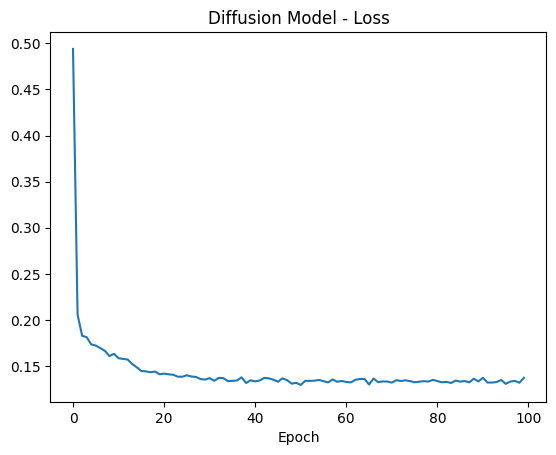

100%|██████████| 100/100 [04:36<00:00,  2.77s/it]


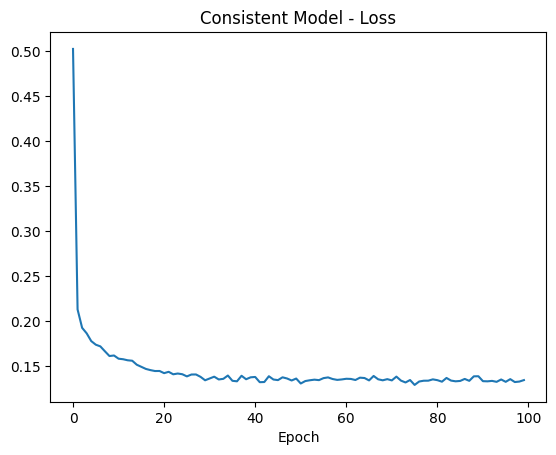

In [ ]:
# now we do the same as before and train a diffusion model on the data
mueller_brown_state = train_loop(state, trajectory, diffusion_loss_fn, 100, 512, jax.random.PRNGKey(0))
plt.title("Diffusion Model - Loss")
plt.show()

# now we do the same as before and train a diffusion model on the data
consistent_mueller_brown_state = train_loop(
    state, trajectory, partial(consistent_loss_fn, alpha=0.001), 100, 512, jax.random.PRNGKey(0)
)
plt.title("Consistent Model - Loss")
plt.show()

## Evaluation of Sampling vs. Simulation
From the Müller-Brown simulation, we observe that iid sampling works well for both models, something that we observed also for high-dimensional systems. Each model captures the modes of the target distribution effectively. However, when we use the learned scores to perform Langevin dynamics, only the Fokker-Planck regularized model produces trajectories that match the training data. This highlights the key finding of our paper:

> Standard diffusion models can sample accurately, but only regularized models yield consistent dynamics.

The regularization ensures that the score aligns not just with the data distirbution, but also with the dynamics governed by the underlying SDE, making the model more consistent.

Simulating: 100%|██████████| 50000/50000 [00:22<00:00, 2188.47it/s]


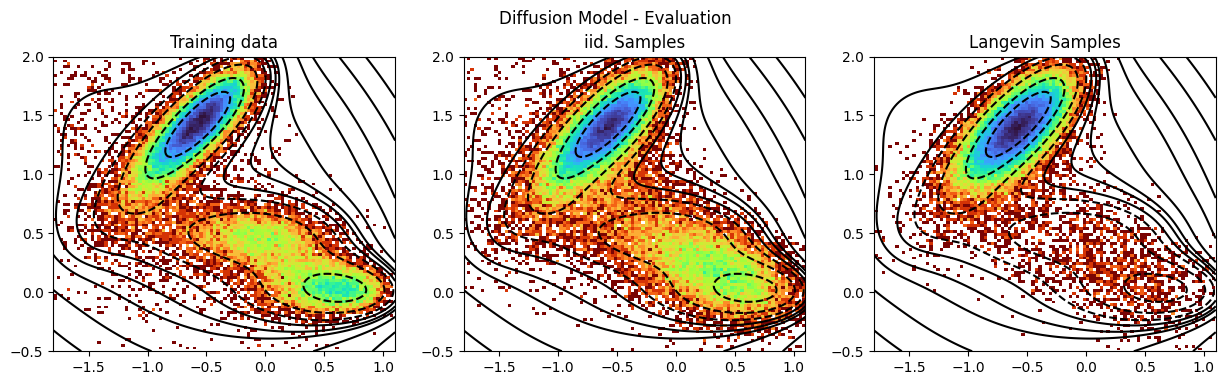

Simulating: 100%|██████████| 50000/50000 [00:22<00:00, 2182.06it/s]


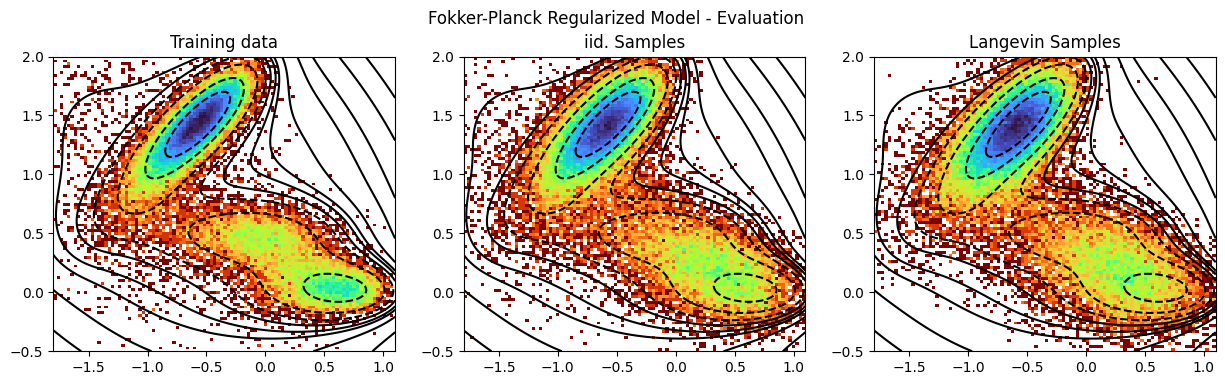

In [ ]:
def evaluate_mueller_brown(key, params):
    plt.figure(figsize=(15, 4))
    plt.subplot(1, 3, 1)
    plt.title("Training data")
    plot_mueller_brown(trajectory)

    plt.subplot(1, 3, 2)
    plt.title("iid. Samples")
    samples = sample(key, params, num_samples=trajectory.shape[0], num_steps=200)
    plot_mueller_brown(samples)

    plt.subplot(1, 3, 3)
    plt.title("Langevin Samples")

    def get_force_fn(params):
        def force(x):
            orig_shape = x.shape
            x = x.reshape(
                -1, 2
            )  # the nice thing here is that we can easily simulate multiple trajectories in parallel.
            forces = model.apply(params, x, jnp.zeros((x.shape[0], 1))) * kbT
            return forces.reshape(orig_shape)

        return force

    simulated_trajectory = simulate_mueller_brown(
        key, get_force_fn(params), num_samples=num_mueller_brown_samples, num_steps=num_mueller_brown_steps
    )

    plot_mueller_brown(simulated_trajectory)


evaluate_mueller_brown(jax.random.PRNGKey(0), mueller_brown_state.params)
plt.suptitle("Diffusion Model - Evaluation")
plt.show()

evaluate_mueller_brown(jax.random.PRNGKey(0), consistent_mueller_brown_state.params)
plt.suptitle("Fokker-Planck Regularized Model - Evaluation")
plt.show()